# ADI Method

## Problem
Same Poisson problem as notebook 04

$$
-(u_{xx} + u_{yy}) = 2\pi^2 \sin(\pi x)\sin(\pi y), \quad u = 0 \text{ on the boundary}
$$

## Discretization
Peaceman-Rachford ADI with $H$ and $V$ the one-dimensional second difference operators in $x$ and $y$

\begin{align*}
(\rho I + H) u^{*} &= (\rho I - V) u^{n} + b \\
(\rho I + V) u^{n+1} &= (\rho I - H) u^{*} + b
\end{align*}

Each half-step is a batch of tridiagonal solves. The single parameter is $\rho = \sqrt{\lambda_{min}\lambda_{max}}$.

## Code

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
from elliptic import jacobi, gauss_seidel, sor, adi

In [2]:
f = lambda X, Y: 2*np.pi**2*np.sin(np.pi*X)*np.sin(np.pi*Y)
ex = lambda X, Y: np.sin(np.pi*X)*np.sin(np.pi*Y)

In [3]:
def run(N):
    h = 1/N
    x = np.linspace(0, 1, N+1)
    X, Y = np.meshgrid(x, x, indexing='ij')
    F = f(X, Y)
    w = 2/(1+np.sin(np.pi*h))
    lmin = 4/h**2*np.sin(np.pi*h/2)**2
    lmax = 4/h**2*np.cos(np.pi*h/2)**2
    rho = np.sqrt(lmin*lmax)
    out = {'N': N}
    for name, fun in [('jacobi', lambda: jacobi(np.zeros_like(X), h, f=F)),
                      ('gs', lambda: gauss_seidel(np.zeros_like(X), h, f=F)),
                      ('sor', lambda: sor(np.zeros_like(X), h, w, f=F)),
                      ('adi', lambda: adi(N, f, rho))]:
        t0 = time.perf_counter()
        u, k = fun()
        out[name] = k
        out[name+'_t'] = time.perf_counter()-t0
    out['adi_err'] = np.max(np.abs(u-ex(X, Y)))
    return out

In [4]:
df = pd.DataFrame([run(N) for N in [8, 16, 32, 64]])
df[['N', 'jacobi', 'gs', 'sor', 'adi']]

,N,jacobi,gs,sor,adi
0,8,144,77,22,18
1,16,510,274,41,34
2,32,1758,952,77,63
3,64,5887,3232,145,118


In [5]:
for c in ['jacobi', 'gs', 'sor', 'adi']:
    print(c, (df[c].shift(-1)/df[c]).round(2).values[:-1])

jacobi [3.54 3.45 3.35]
gs [3.56 3.47 3.39]
sor [1.86 1.88 1.88]
adi [1.89 1.85 1.87]


### Iterations

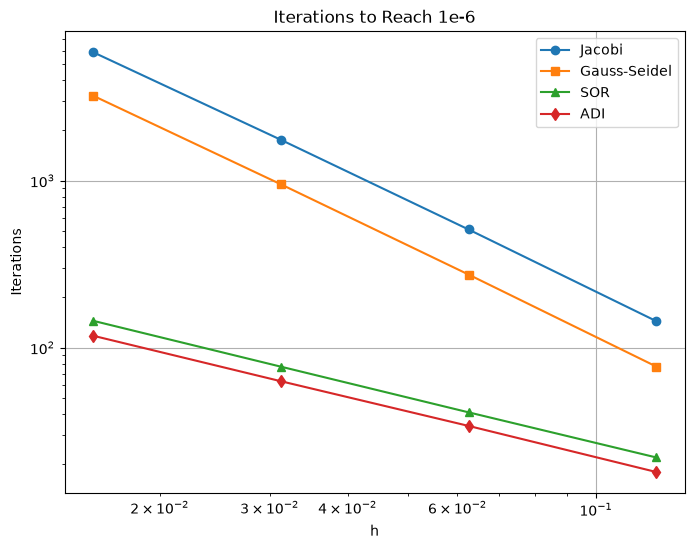

In [6]:
h = 1/df['N'].values
plt.figure(figsize=(8, 6))
plt.loglog(h, df['jacobi'], 'o-', label="Jacobi")
plt.loglog(h, df['gs'], 's-', label="Gauss-Seidel")
plt.loglog(h, df['sor'], '^-', label="SOR")
plt.loglog(h, df['adi'], 'd-', label="ADI")
plt.xlabel("h")
plt.ylabel("Iterations")
plt.title("Iterations to Reach 1e-6")
plt.legend()
plt.grid(True)
plt.savefig("../figures/06_iterations.png", dpi=300, bbox_inches="tight")
plt.show()

### Runtime

In [7]:
df[['N', 'jacobi_t', 'gs_t', 'sor_t', 'adi_t']]

,N,jacobi_t,gs_t,sor_t,adi_t
0,8,0.002084,0.002369,0.000744,0.004607
1,16,0.008230,0.010465,0.001614,0.055079
2,32,0.056739,0.062530,0.005677,0.016921
3,64,0.262888,0.528277,0.023918,0.041324


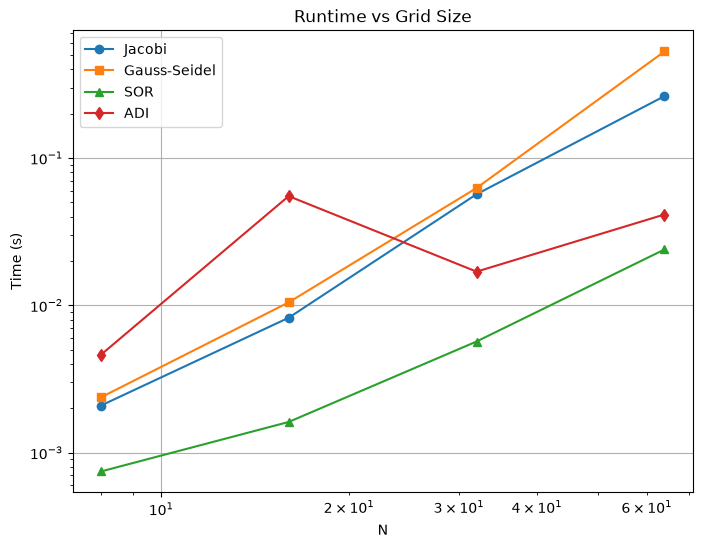

In [8]:
plt.figure(figsize=(8, 6))
plt.loglog(df['N'], df['jacobi_t'], 'o-', label="Jacobi")
plt.loglog(df['N'], df['gs_t'], 's-', label="Gauss-Seidel")
plt.loglog(df['N'], df['sor_t'], '^-', label="SOR")
plt.loglog(df['N'], df['adi_t'], 'd-', label="ADI")
plt.xlabel("N")
plt.ylabel("Time (s)")
plt.title("Runtime vs Grid Size")
plt.legend()
plt.grid(True)
plt.savefig("../figures/06_runtime.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
ADI needs 118 iterations at N = 64 against 5887 for Jacobi, and its count doubles with N like SOR. SOR is still faster in runtime here because each ADI iteration does two sets of tridiagonal solves.